In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

import pandas as pd
import matplotlib.pyplot as plot
import matplotlib.dates as mdates
import seaborn as sns
import time
from datetime import datetime, timedelta, date
import teradata
from plotly.offline import plot as plt
import plotly.graph_objs as go
import plotly.io as pio
import plotly.express as px
import teradata
import businessdays as bzd



start = time.time() 
system = "TERADBAWS.sicredi.net"
user = "P_USR_DL_GESTAO_RECURSOS"
passw = "JAW0b71329aadade35365afc6X"
udaExec = teradata.UdaExec (appName="TESTE", version="1.0", logConsole=False)
session = udaExec.connect(method="odbc", system=system,
      username=user, password=passw, Authentication="TDNEGO");


select_feriados = "Select DT from dl_Gestao_recursos.bas_cad_fer where tipo in ('3','2')"
feriados = pd.read_sql(select_feriados, session)
cal = bzd.Calendar(holidays=feriados.DT,weekdays=['Sunday','Saturday'])

data_inicial = cal.offset(datetime.now(),-180  )###DATA PADRÃO D-180
data_inicial = data_inicial.strftime('%Y-%m-%d') ###DATA PADRÃO D-180

data_final = cal.offset(datetime.now(),-1  )###DATA PADRÃO D-1
data_final = data_final.strftime('%Y-%m-%d') ###DATA PADRÃO D-1

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_15392\4105129518.py:30: UserWarning:

pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.



In [2]:
def FLY(lista_fly, dt_inicial = (date.today()+ timedelta(days=-365)).strftime('%d/%m/%Y'), dt_final = (date.today()).strftime('%d/%m/%Y'), graf_resultado = False, fim_mes = True):
    
    lista_string = "','".join(map(str,lista_fly))
    data_inicial = datetime.strptime(dt_inicial, "%d/%m/%Y").date()
    data_final = datetime.strptime(dt_final, "%d/%m/%Y").date()
    dt_final_sql = data_final.strftime('%Y-%m-%d')
    dt_inicial_sql = data_inicial.strftime('%Y-%m-%d')

    Select = f"""
    SELECT DT
    , FLY
    , FLY_PONTOS AS TAXA

    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MEDIA_6M
    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) + 2*(STDDEV_SAMP(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_SUP_6M
    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) - 2*(STDDEV_SAMP(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_INF_6M
    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 21 PRECEDING AND CURRENT ROW) AS MEDIA_21
    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 21 PRECEDING AND CURRENT ROW) + 2*(STDDEV_SAMP(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 21 PRECEDING AND CURRENT ROW)) as LIM_SUP_21
    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 21 PRECEDING AND CURRENT ROW) - 2*(STDDEV_SAMP(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 21 PRECEDING AND CURRENT ROW)) as LIM_INF_21
    , MIN(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MINIMO_6M
    , MAX(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MAXIMO_6M
    , STDDEV_SAMP(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS DEVPAD_AM_6M
    , FWD_AB
    , SPREAD_AB
    , CDI
    , FL_FIM_MES

    FROM 
    (SELECT DI_B.DATA as DT
    , to_char(ROUND(CAST(DI_A.VERTICE AS FLOAT)/252,2))  || 'x' || TO_CHAR(ROUND(CAST(DI_B.VERTICE AS FLOAT)/252,2)) || 'x' || TO_CHAR(ROUND(CAST(DI_C.VERTICE AS FLOAT)/252,2)) AS FLY
    , DI_A.VERTICE AS CONTRATO_A, DI_B.VERTICE AS CONTRATO_B, DI_C.VERTICE AS CONTRATO_C
    , DI_A.TAXA AS TAXA_A, DI_B.TAXA AS TAXA_B, DI_C.TAXA AS TAXA_C
    , ((1+DI_B.TAXA)**(CAST(DI_B.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE))/(1+DI_A.TAXA)**(CAST(DI_A.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE)))-1 AS FWD_AB
    , ((1+DI_C.TAXA)**(CAST(DI_C.VERTICE AS FLOAT)/(DI_C.VERTICE-DI_B.VERTICE))/(1+DI_B.TAXA)**(CAST(DI_B.VERTICE AS FLOAT)/(DI_C.VERTICE-DI_B.VERTICE)))-1 AS FWD_BC
    ,  (1+DI_C.TAXA)**(CAST(DI_C.VERTICE AS FLOAT)/(DI_C.VERTICE-DI_B.VERTICE))/(1+DI_B.TAXA)**(CAST(DI_B.VERTICE AS FLOAT)/(DI_C.VERTICE-DI_B.VERTICE)) - (1+DI_B.TAXA)**(CAST(DI_B.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE))/(1+DI_A.TAXA)**(CAST(DI_A.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE)) AS FLY_ABC
    ,  (DI_B.TAXA - DI_A.TAXA) as SPREAD_AB
    ,  (DI_C.TAXA - DI_B.TAXA) as SPREAD_BC
    ,  (DI_C.TAXA - DI_B.TAXA) - (DI_B.TAXA - DI_A.TAXA) as FLY_PONTOS
    , (CAST(DI_B.VERTICE AS FLOAT)/(1+DI_B.TAXA) - CAST(DI_C.VERTICE AS FLOAT)/(1+DI_C.TAXA))/(CAST(DI_A.VERTICE AS FLOAT)/(1+DI_A.TAXA)-CAST(DI_C.VERTICE AS FLOAT)/(1+DI_C.TAXA)) AS ALFA
    , ((IDX.VALOR/3000+1)**252.000000-1)*100 AS CDI
    , NVL(DU.FL_FIM_MES, DU.FL_D1) AS FL_FIM_MES

    FROM DL_GESTAO_RECURSOS.CURVA DI_B
    LEFT JOIN DL_GESTAO_RECURSOS.CURVA DI_A ON DI_A.DATA = DI_B.DATA AND DI_A.VERTICE < DI_B.VERTICE
    LEFT JOIN DL_GESTAO_RECURSOS.CURVA DI_C ON DI_C.DATA = DI_B.DATA AND DI_C.VERTICE > DI_B.VERTICE
    LEFT JOIN DL_GESTAO_RECURSOS.IDX_INDEX IDX ON IDX.DATA = DI_B.DATA AND IDX.CODINDEX = 'CDI'
    LEFT JOIN dl_Gestao_recursos.vw_du DU ON DU.DT = DI_B.DATA AND (DU.FL_FIM_MES = 1 or du.fl_d1 = 1)

    --WHERE 
    --DI_B.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')
    --and DI_A.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')
    --and DI_C.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')
    ) VW

    WHERE VW.DT between '{data_inicial}' and '{data_final}'
    AND VW.FLY IN ('{lista_string}')
    """

    
    fly = pd.read_sql(Select, session) 
    fly.DT = pd.to_datetime(fly.DT, format='%Y-%m-%d')

    for x in lista_fly:     
        fly_grafico = fly[fly.FLY == x]
        fly_grafico = fly_grafico.sort_values(by=['DT'])
        fly_nome = x
        fly_grafico = fly_grafico[fly_grafico.FL_FIM_MES == 1]
        #fly_grafico = fly_grafico[fly_grafico.DT >= datetime(2021,12,30)]
        fly_grafico = fly_grafico.reset_index() 
        pd.set_option('mode.chained_assignment', None)

        sns.set(style="darkgrid", palette="Set2")
        plot.rcParams['figure.figsize'] = (14,7)

        fig, ax = plot.subplots()
        ax2 = ax.twinx()
        ax.plot(fly_grafico.DT,fly_grafico['TAXA']*10000, marker = '', color='dodgerblue',linestyle='-',linewidth=1,)
        ax.plot(fly_grafico.DT,fly_grafico['MEDIA_6M']*10000, marker='', color='gold',linestyle='--',linewidth=1)
        ax.plot(fly_grafico.DT,fly_grafico['LIM_INF_6M']*10000, marker='', color='gold',linestyle='-',linewidth=1)
        ax.plot(fly_grafico.DT,fly_grafico['LIM_SUP_6M']*10000, marker='', color='gold',linestyle='-',linewidth=1)
        ax.axvspan(datetime(2004,8,30),datetime(2005,5,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2008,3,31),datetime(2008,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2010,3,19),datetime(2010,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2011,1,2),    datetime(2011,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2013,4,18),    datetime(2014,4,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2014,11,15), datetime(2015,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2021,3,16),    datetime(2022,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2005,8,30),datetime(2007,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2009,1,5),datetime(2009,7,31), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2011,8,20),datetime(2012,11,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2016,9,30), datetime(2018,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2019,6,22),datetime(2020,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2023,9,1),datetime(2024,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
        ax.axvspan(datetime(2024,9,1),datetime(2025,1,1), color="grey", alpha=0.2,ymin=0, ymax=100)
        ax2.plot(fly_grafico.DT,fly_grafico['CDI'], marker='', color='violet',linestyle='--',linewidth=1)
        ax.set_ylabel('Taxa', color='dodgerblue')
        ax2.set_ylabel('CDI', color='violet',labelpad=None)
        ax2.grid(visible=False)
        ax.legend(loc='upper center')

        #ax.plot_date(fly_grafico.DT,fly_grafico['SUP_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
        #ax.plot_date(fly_grafico.DT,fly_grafico['INF_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
        plot.title(fly_nome)
        #plot.ylabel('Taxa')
        plot.xlabel('Data')
        fig.autofmt_xdate()
        ax.fmt_xdata = mdates.DateFormatter('%Y-%m')
        plot.show()
        #plt.savefig('FLY.png', transparent = True)
        #fly_grafico.set_index('DT',inplace=True)


C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_5024\3491336716.py:60: UserWarning:

pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.



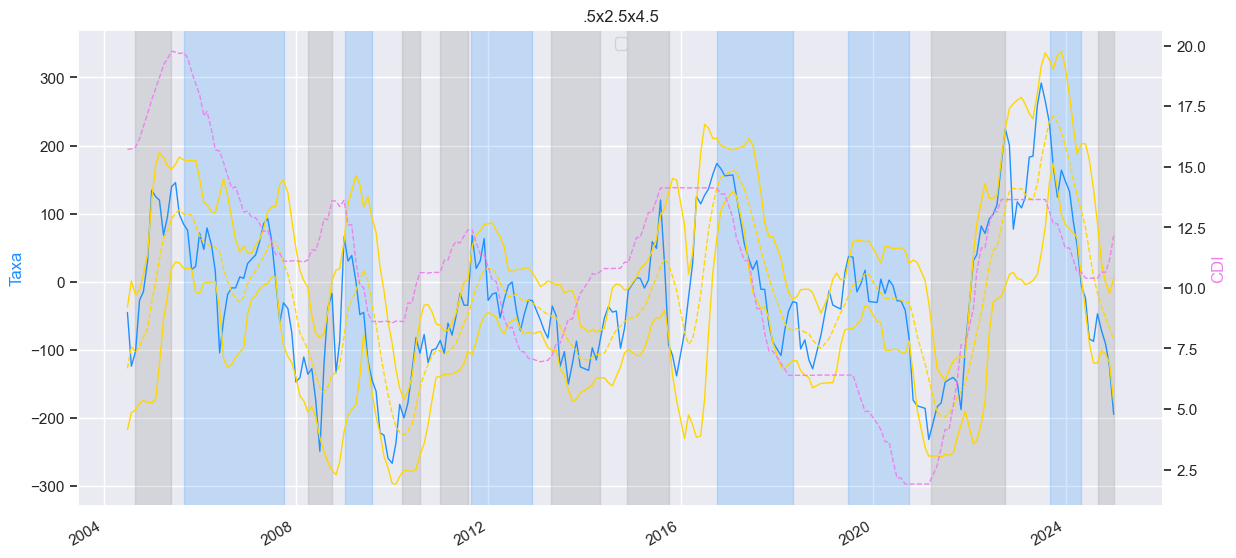

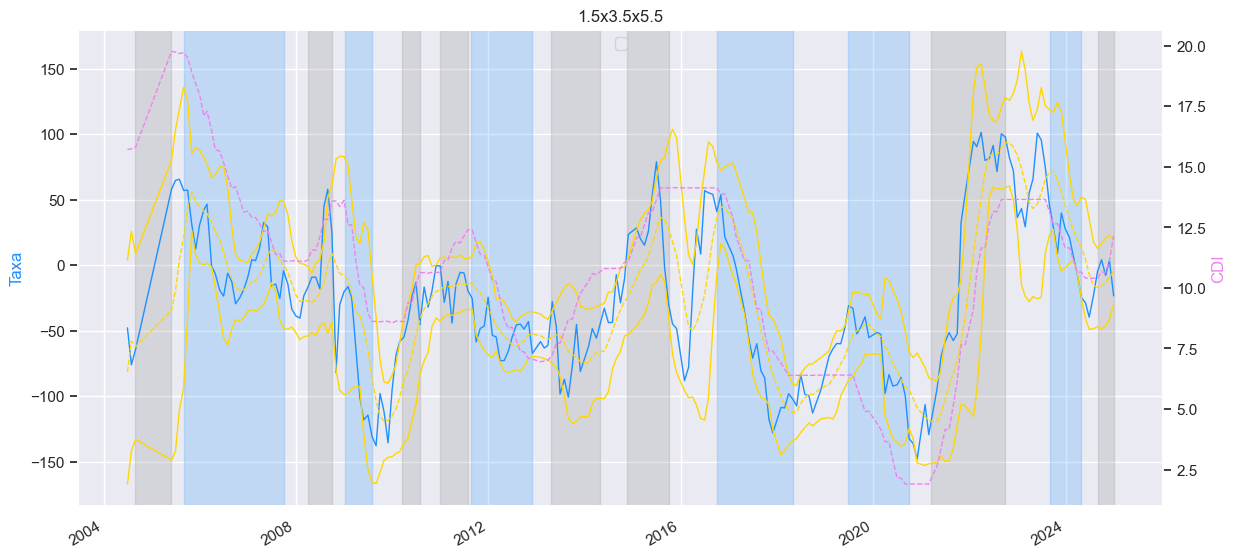

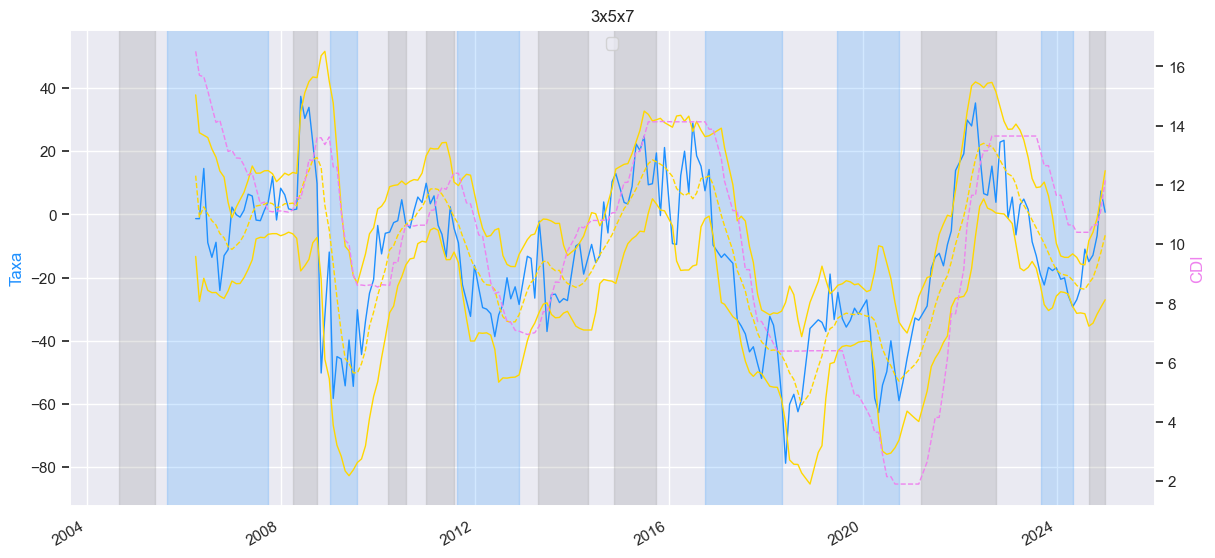

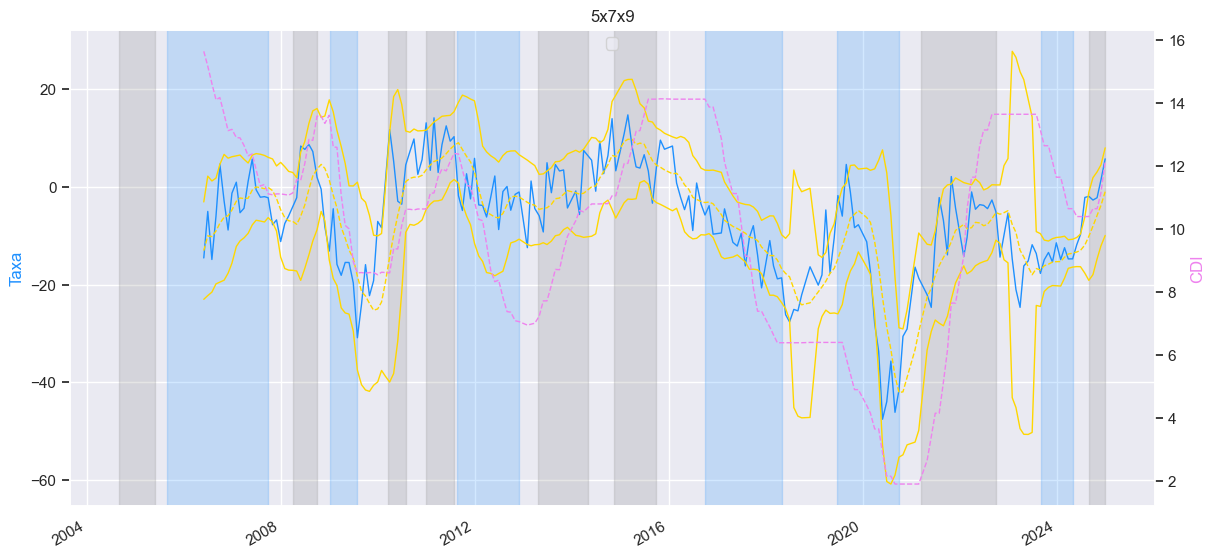

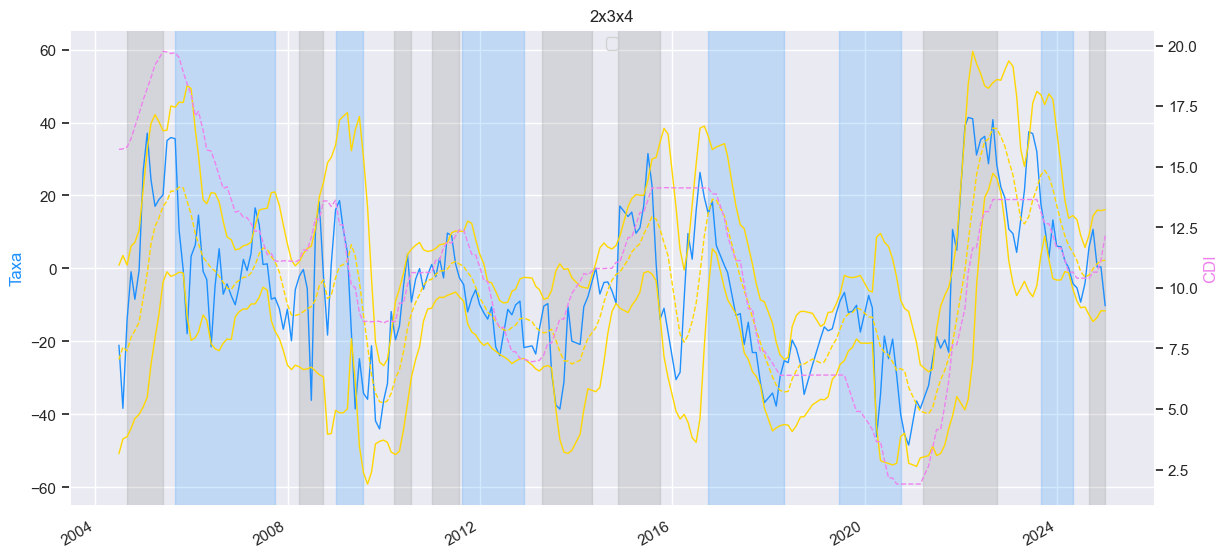

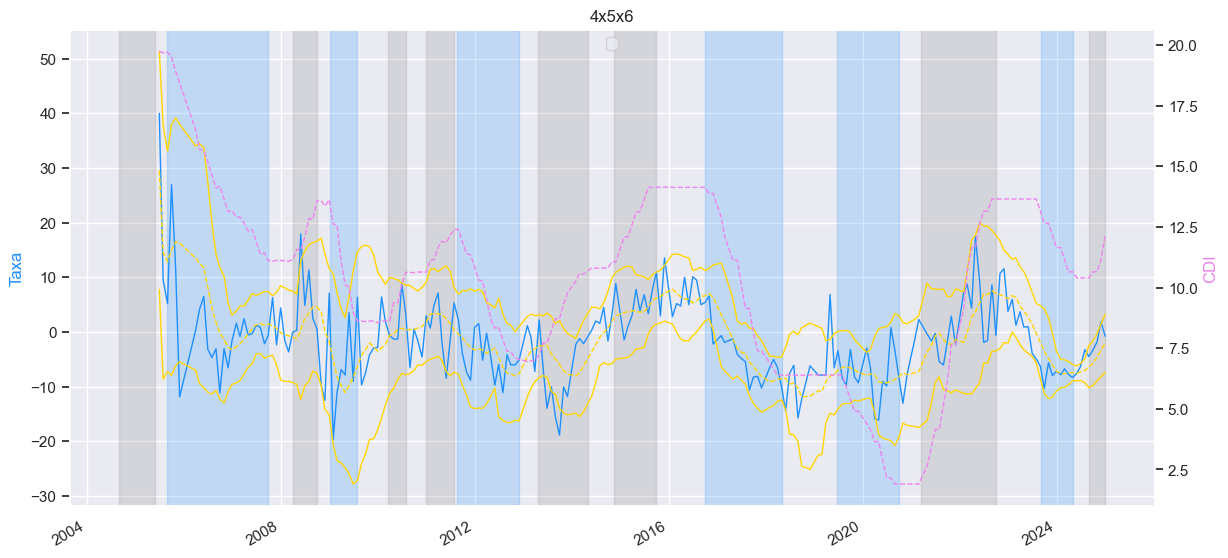

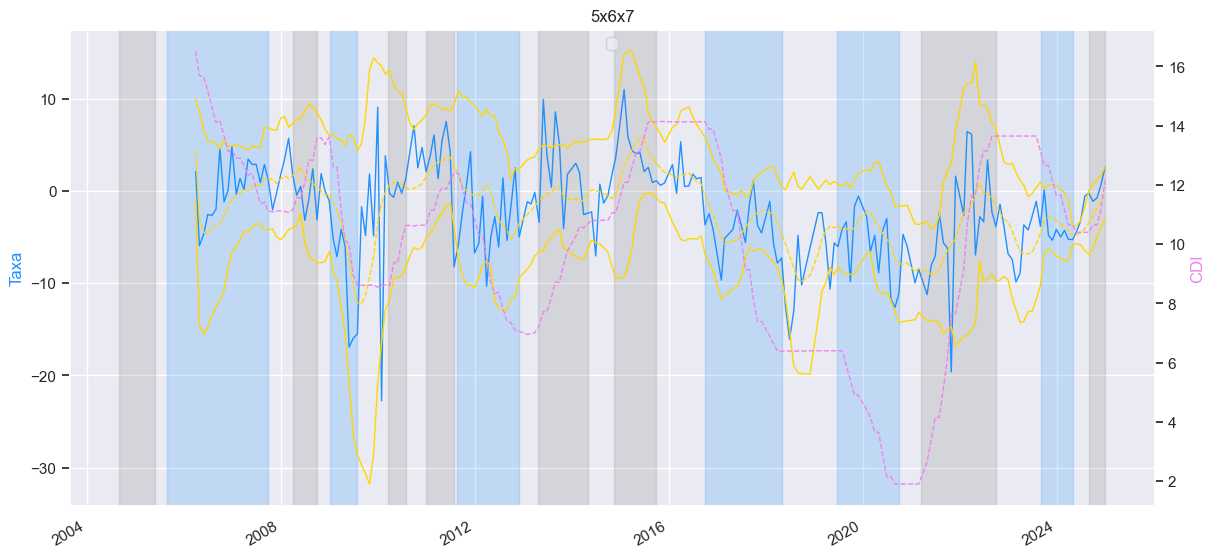

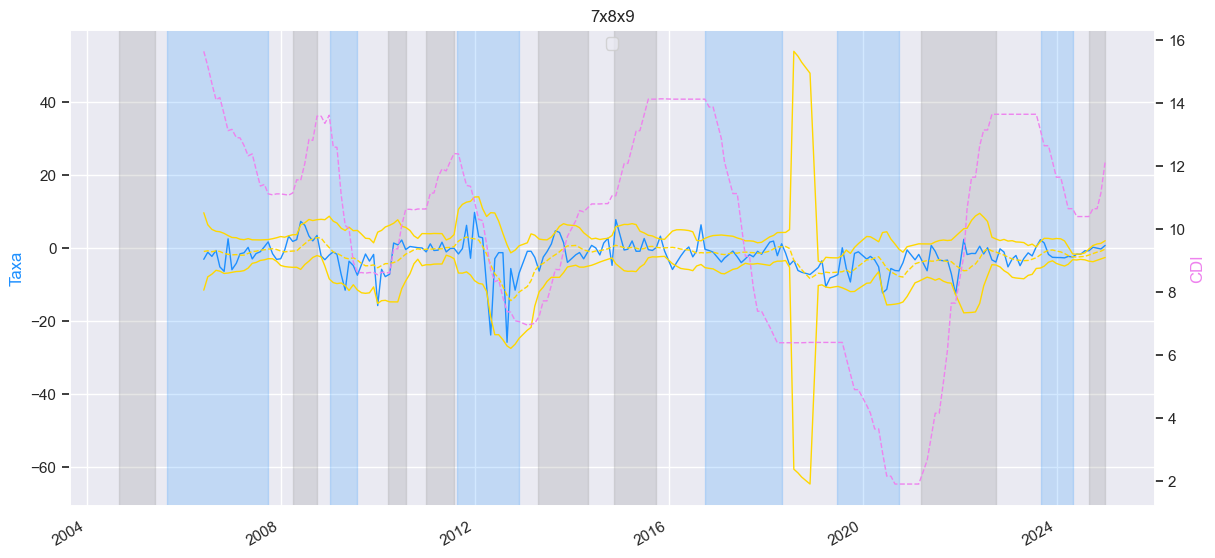

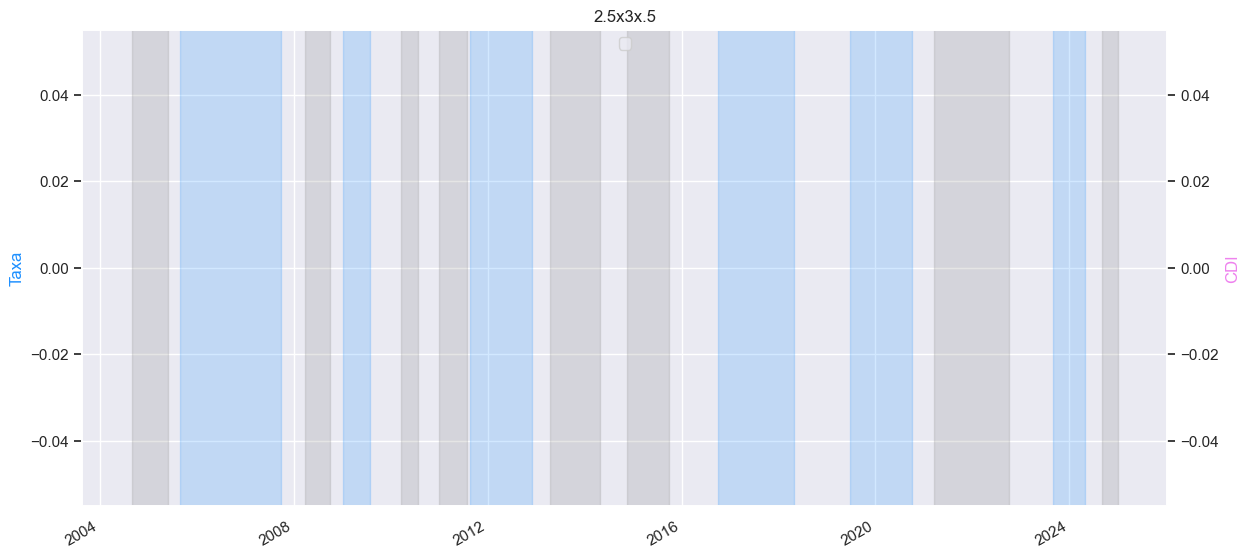

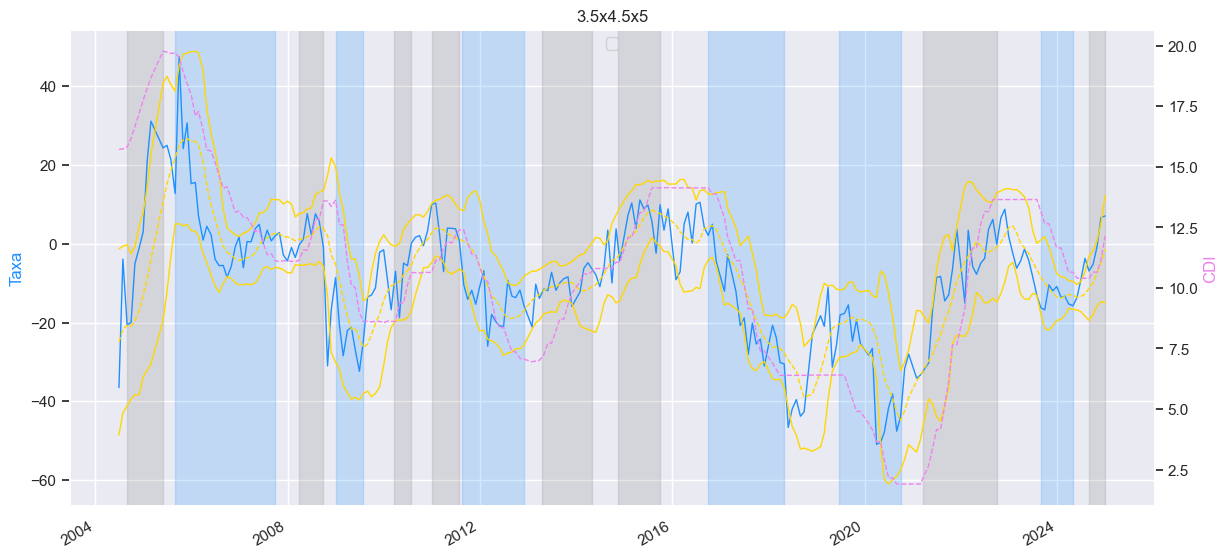

In [5]:
lista = ['.5x2.5x4.5','1.5x3.5x5.5','3x5x7','5x7x9','2x3x4','4x5x6','5x6x7','7x8x9','2.5x3x.5','3.5x4.5x5']

lista_reduzida = ['1x3x5','2x4x6','3x5x7','5x7x9']

lista_fly = [ 
 '.5x.75x1','.5x1.5x2.5','.5x1.5x3.5','.5x2.5x4.5','.75x1.25x1.75','.75x1x1.25'
,'1.25x1.5x1.75','1.25x1.75x2.25','1.5x1.75x2','1.5x2.5x3.5','1.5x2x2.5','1.75x2x2.25','1x1.25x1.5','1x1.5x2'
,'1x2x3','1x2x4','1x3x4','1x3x5','1x3x6','1x4x5','1x4x6','1x4x7','1x5x9','2.5x3.5x4.5','2.5x3x3.5'
,'2x2.25x2.5','2x2.5x3','2x3.5x5','2x3x4','2x3x5' ,'2x4x6','2x5x8','3.5x4x4.5','3x3.5x4','3x4x5','3x5x7','3x6x9','4x4.5x5'
,'4x5x6','4x6x8','4x7x10','5x6x7','5x7x9','6x7x9']


FLY(lista,'01/06/2004','01/01/2025')

In [4]:

fly = pd.read_sql(Select, session) 
fly.DT = pd.to_datetime(fly.DT, format='%Y-%m-%d')

for x in lista_fly:     
    fly_grafico = fly[fly.FLY == x]
    fly_grafico = fly_grafico.sort_values(by=['DT'])
    fly_nome = x
    fly_grafico = fly_grafico[fly_grafico.FL_FIM_MES == 1]
    #fly_grafico = fly_grafico[fly_grafico.DT >= datetime(2021,12,30)]
    fly_grafico = fly_grafico.reset_index() 
    pd.set_option('mode.chained_assignment', None)
    
    sns.set(style="darkgrid", palette="Set2")
    plot.rcParams['figure.figsize'] = (14,7)

    fig, ax = plot.subplots()
    ax2 = ax.twinx()
    ax.plot(fly_grafico.DT,fly_grafico['TAXA']*10000, marker = '', color='dodgerblue',linestyle='-',linewidth=1,)
    ax.plot(fly_grafico.DT,fly_grafico['MEDIA_6M']*10000, marker='', color='gold',linestyle='--',linewidth=1)
    ax.plot(fly_grafico.DT,fly_grafico['LIM_INF_6M']*10000, marker='', color='gold',linestyle='-',linewidth=1)
    ax.plot(fly_grafico.DT,fly_grafico['LIM_SUP_6M']*10000, marker='', color='gold',linestyle='-',linewidth=1)
    ax.axvspan(datetime(2004,8,30),datetime(2005,5,30), color="grey", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2008,3,31),datetime(2008,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2010,3,19),datetime(2010,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2011,1,2),    datetime(2011,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2013,4,18),    datetime(2014,4,30), color="grey", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2014,11,15), datetime(2015,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2021,3,16),    datetime(2022,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2005,8,30),datetime(2007,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2009,1,5),datetime(2009,7,31), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2011,8,20),datetime(2012,11,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2016,9,30), datetime(2018,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
    ax.axvspan(datetime(2019,6,22),datetime(2020,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
    ax2.plot(fly_grafico.DT,fly_grafico['CDI'], marker='', color='violet',linestyle='--',linewidth=1)
    ax.set_ylabel('Taxa', color='dodgerblue')
    ax2.set_ylabel('CDI', color='violet',labelpad=None)
    ax2.grid(visible=False)
    ax.legend(loc='upper center')

    #ax.plot_date(fly_grafico.DT,fly_grafico['SUP_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
    #ax.plot_date(fly_grafico.DT,fly_grafico['INF_MDL']*10000, marker='', color='violet',linestyle='-',linewidth=1)
    plot.title(fly_nome)
    #plot.ylabel('Taxa')
    plot.xlabel('Data')
    fig.autofmt_xdate()
    ax.fmt_xdata = mdates.DateFormatter('%Y-%m')
    plot.show()
    #plt.savefig('FLY.png', transparent = True)
    #fly_grafico.set_index('DT',inplace=True)





NameError: name 'Select' is not defined

In [ ]:
import matplotlib.pyplot as plot

fly = fly.sort_values(by=['DT','FLY'])
df_grafico = fly[fly['FLY'].isin(lista_reduzida)]
df_grafico = df_grafico[df_grafico.FL_FIM_MES == 1]
#df_grafico = df_grafico[df_grafico.DT >= datetime(2008,12,30)]

sns.set(style="darkgrid", palette="Set2")
ax1 = sns.lineplot(x='DT', y='TAXA', data=df_grafico, hue='FLY')
ax2 = ax1.twinx()
ax1.axvspan(datetime(2004,8,30),datetime(2005,5,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2008,3,31),datetime(2008,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2010,3,19),datetime(2010,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2011,1,2),    datetime(2011,7,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2013,4,18),    datetime(2014,4,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2014,11,15), datetime(2015,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2021,3,16),    datetime(2022,9,30), color="grey", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2005,8,30),datetime(2007,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2009,1,5),datetime(2009,7,31), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2011,8,20),datetime(2012,11,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2016,9,30), datetime(2018,4,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax1.axvspan(datetime(2019,6,22),datetime(2020,9,30), color="dodgerblue", alpha=0.2,ymin=0, ymax=100)
ax2 = sns.lineplot(x='DT', y='CDI', data=df_grafico, color='violet',linestyle='--',linewidth=1)
ax1.set(title='Histórico FLY Spreads')
plot.show()

In [ ]:
def FLY_HTML(lista_fly, dt_inicial = (date.today()+ timedelta(days=-365)).strftime('%d/%m/%Y'), dt_final = (date.today()).strftime('%d/%m/%Y'), fim_mes = True):
    
    lista_string = "','".join(map(str,lista_fly))
    data_inicial = datetime.strptime(dt_inicial, "%d/%m/%Y").date()
    data_final = datetime.strptime(dt_final, "%d/%m/%Y").date()
    dt_final_sql = data_final.strftime('%Y-%m-%d')
    dt_inicial_sql = data_inicial.strftime('%Y-%m-%d')

    Select = f"""
    SELECT DT
    , FLY
    , FLY_PONTOS AS TAXA

    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MEDIA_6M
    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) + 2*(STDDEV_SAMP(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_SUP_6M
    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) - 2*(STDDEV_SAMP(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_INF_6M
    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 21 PRECEDING AND CURRENT ROW) AS MEDIA_21
    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 21 PRECEDING AND CURRENT ROW) + 2*(STDDEV_SAMP(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 21 PRECEDING AND CURRENT ROW)) as LIM_SUP_21
    , AVG(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 21 PRECEDING AND CURRENT ROW) - 2*(STDDEV_SAMP(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 21 PRECEDING AND CURRENT ROW)) as LIM_INF_21
    , MIN(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MINIMO_6M
    , MAX(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MAXIMO_6M
    , STDDEV_SAMP(FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS DEVPAD_AM_6M
    , FWD_AB
    , SPREAD_AB
    , CDI
    , FL_FIM_MES

    FROM 
    (SELECT DI_B.DATA as DT
    , to_char(ROUND(CAST(DI_A.VERTICE AS FLOAT)/252,2))  || 'x' || TO_CHAR(ROUND(CAST(DI_B.VERTICE AS FLOAT)/252,2)) || 'x' || TO_CHAR(ROUND(CAST(DI_C.VERTICE AS FLOAT)/252,2)) AS FLY
    , DI_A.VERTICE AS CONTRATO_A, DI_B.VERTICE AS CONTRATO_B, DI_C.VERTICE AS CONTRATO_C
    , DI_A.TAXA AS TAXA_A, DI_B.TAXA AS TAXA_B, DI_C.TAXA AS TAXA_C
    , ((1+DI_B.TAXA)**(CAST(DI_B.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE))/(1+DI_A.TAXA)**(CAST(DI_A.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE)))-1 AS FWD_AB
    , ((1+DI_C.TAXA)**(CAST(DI_C.VERTICE AS FLOAT)/(DI_C.VERTICE-DI_B.VERTICE))/(1+DI_B.TAXA)**(CAST(DI_B.VERTICE AS FLOAT)/(DI_C.VERTICE-DI_B.VERTICE)))-1 AS FWD_BC
    ,  (1+DI_C.TAXA)**(CAST(DI_C.VERTICE AS FLOAT)/(DI_C.VERTICE-DI_B.VERTICE))/(1+DI_B.TAXA)**(CAST(DI_B.VERTICE AS FLOAT)/(DI_C.VERTICE-DI_B.VERTICE)) - (1+DI_B.TAXA)**(CAST(DI_B.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE))/(1+DI_A.TAXA)**(CAST(DI_A.VERTICE AS FLOAT)/(DI_B.VERTICE-DI_A.VERTICE)) AS FLY_ABC
    ,  (DI_B.TAXA - DI_A.TAXA) as SPREAD_AB
    ,  (DI_C.TAXA - DI_B.TAXA) as SPREAD_BC
    ,  (DI_C.TAXA - DI_B.TAXA) - (DI_B.TAXA - DI_A.TAXA) as FLY_PONTOS
    , (CAST(DI_B.VERTICE AS FLOAT)/(1+DI_B.TAXA) - CAST(DI_C.VERTICE AS FLOAT)/(1+DI_C.TAXA))/(CAST(DI_A.VERTICE AS FLOAT)/(1+DI_A.TAXA)-CAST(DI_C.VERTICE AS FLOAT)/(1+DI_C.TAXA)) AS ALFA
    , ((IDX.VALOR/3000+1)**252.000000-1)*100 AS CDI
    , NVL(DU.FL_FIM_MES, DU.FL_D1) AS FL_FIM_MES

    FROM DL_GESTAO_RECURSOS.CURVA DI_B
    LEFT JOIN DL_GESTAO_RECURSOS.CURVA DI_A ON DI_A.DATA = DI_B.DATA AND DI_A.VERTICE < DI_B.VERTICE
    LEFT JOIN DL_GESTAO_RECURSOS.CURVA DI_C ON DI_C.DATA = DI_B.DATA AND DI_C.VERTICE > DI_B.VERTICE
    LEFT JOIN DL_GESTAO_RECURSOS.IDX_INDEX IDX ON IDX.DATA = DI_B.DATA AND IDX.CODINDEX = 'CDI'
    LEFT JOIN dl_Gestao_recursos.vw_du DU ON DU.DT = DI_B.DATA AND (DU.FL_FIM_MES = 1 or du.fl_d1 = 1)

    --WHERE 
    --DI_B.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')
    --and DI_A.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')
    --and DI_C.VERTICE IN ('126','189','252','315','378','441','504','567','630','756','882','1008','1134','1260','1512','1764','2016','2268','2520')
    ) VW

    WHERE VW.DT between '{data_inicial}' and '{data_final}'
    AND VW.FLY IN ('{lista_string}')
    """

    
    fly = pd.read_sql(Select, session) 
    fly.DT = pd.to_datetime(fly.DT, format='%Y-%m-%d')

    if fim_mes  == True:
        fly_df = fly[fly.FL_FIM_MES == 1]
   
    for x in lista_fly:   
        fly_grafico = fly_df[fly_df.FLY == x] 
        fly_grafico = fly_grafico.sort_values(by=['DT'])
        fly_grafico = fly_grafico.reset_index() 
        fly_grafico = fly_grafico[fly_grafico.FL_FIM_MES == 1]
        pd.set_option('mode.chained_assignment', None)
    
        #fig = make_subplots(specs=[[{"secondary_y": True}]])
        #fig.add_vline(x=datetime(2014,11,15), line_width=3, line_dash="dash", line_color="green")
        TAXA = go.Scatter(x = fly_grafico.DT,y = fly_grafico['TAXA']*10000,mode = 'lines', name = 'Taxa', line = {'color': 'dodgerblue', 'width':1.5}, yaxis = 'y1')
        MEDIA = go.Scatter(x = fly_grafico.DT,y = fly_grafico['MEDIA_6M']*10000,mode = 'lines', name = 'Media', line = {'color': 'violet', 'width':1.5},yaxis = 'y1')
        LIM_INF = go.Scatter(x = fly_grafico.DT,y = fly_grafico['LIM_INF_6M']*10000,mode = 'lines', name = 'Liminte Inferior', line = {'color': 'violet','width':1},yaxis = 'y1')
        LIM_SUP = go.Scatter(x = fly_grafico.DT,y = fly_grafico['LIM_SUP_6M']*10000,mode = 'lines', name = 'Limite Superior', line = {'color': 'violet','width':1},yaxis = 'y1')
    
        CDI = go.Scatter(x = fly_grafico.DT,y = fly_grafico['CDI'],mode = 'lines', name = 'CDI', line = {'color': 'goldenrod', 'width':0.5,'dash':'dash'}, yaxis = 'y2')
      
        data  = [TAXA, MEDIA, LIM_SUP,LIM_INF, CDI]
        layout = dict(title = x,
                           xaxis = dict(title = 'Data')
                           ,yaxis = dict(title = 'Taxa')
                           #,xaxis_rangeslider_visible=True
                           ,yaxis2=dict(title='CDI',
                                       overlaying='y1',
                                       side='right')
                           )

        fig = dict(data=data, layout=layout)
        pio.show(fig)  
        end = time.time()
        print("Execution Time: %s secs." % "{:.2f}".format(end-start))

In [ ]:
FLY_HTML(['.5x2.5x4.5'],'01/06/2001','01/07/2024')

In [ ]:
lista = ['.5x.75x1','.5x1.5x2.5','.5x1.5x3.5','.5x2.5x4.5','.75x1.25x1.75','.75x1x1.25'
,'1.25x1.5x1.75','1.25x1.75x2.25','1.5x1.75x2','1.5x2.5x3.5','1.5x2x2.5','1.75x2x2.25','1x1.25x1.5','1x1.5x2'
,'1x2x3','1x2x4','1x3x4','1x3x5','1x3x6','1x4x5','1x4x6','1x4x7','1x5x9','2.5x3.5x4.5','2.5x3x3.5'
,'2x2.25x2.5','2x2.5x3','2x3.5x5','2x3x4','2x3x5' ,'2x4x6','2x5x8','3.5x4x4.5','3x3.5x4','3x4x5','3x5x7','3x6x9','4x4.5x5'
,'4x5x6','4x6x8','4x7x10','5x6x7','5x7x9','6x7x9']

FLY_HTML(lista,'01/06/2001','01/07/2024')